
### EXPERIMENT NO. 9
### OBJECT DETECTION AND RECOGNITION USING DEEP LEARNING MODELS
### ON STANDARD IMAGE DATASETS

### Name       : Akshit Negi
### CUID        : CU24250214
### Course     : B.Tech CSE
### Section    : CSE "B"
### Roll No.   : 04

### AIM


### To implement a deep learning-based object detection and
### recognition system using a pre-trained model and evaluate
### its performance for identifying and localizing multiple
### objects in an image.


STEP 1: IMPORT REQUIRED LIBRARIES

In [1]:
!pip install ultralytics
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO
import tkinter as tk
from tkinter import filedialog

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 68.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.2/53.2 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.9/89.9 kB 9.9 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


STEP 2: LOAD PRE-TRAINED YOLO MODEL

In [2]:
# Load the pre-trained YOLOv8 model.
# YOLOv8 is trained on the COCO dataset.

model = YOLO("yolov8n.pt")

 STEP 3: SELECT IMAGE FROM COMPUTER

In [3]:
from google.colab import files
import io
import numpy as np

print("Please upload an image file.")
uploaded = files.upload()

if not uploaded:
    raise ValueError("No image selected.")

# Assuming only one file is uploaded for simplicity
filename = next(iter(uploaded))
image_bytes = uploaded[filename]

# Read the image bytes using OpenCV
image = cv2.imdecode(np.frombuffer(image_bytes, np.uint8), cv2.IMREAD_COLOR)

if image is None:
    raise ValueError("Unable to read the selected image.")

image_rgb = cv2.cvtColor(
    image,
    cv2.COLOR_BGR2RGB
)

Please upload an image file.


Saving 1292433.jpg to 1292433.jpg


STEP 4: DISPLAY ORIGINAL IMAGE

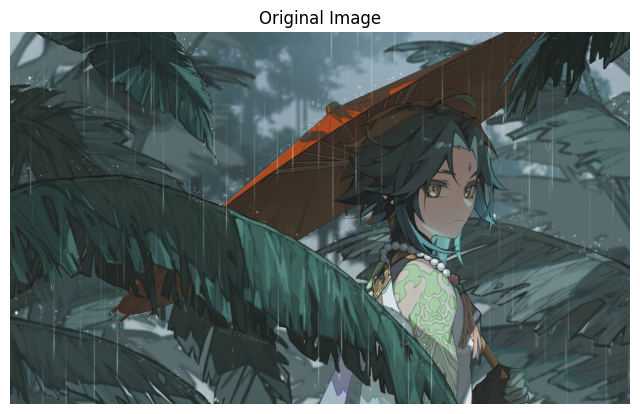

In [4]:
plt.figure(figsize=(8, 6))

plt.imshow(image_rgb)

plt.title("Original Image")

plt.axis("off")

plt.show()

 STEP 5: IMAGE PREPROCESSING

In [5]:
resized_image = cv2.resize(
    image_rgb,
    (640, 640)
)

STEP 6: DISPLAY PREPROCESSED IMAGE

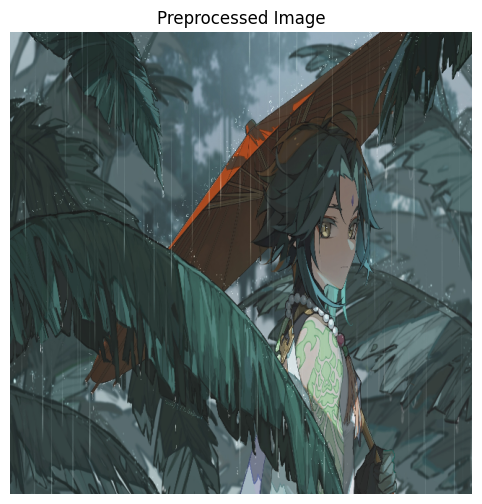

In [6]:
plt.figure(figsize=(8, 6))

plt.imshow(resized_image)

plt.title("Preprocessed Image")

plt.axis("off")

plt.show()

STEP 7: PERFORM OBJECT DETECTION

In [7]:
results = model(image_rgb)

result = results[0]


0: 384x640 (no detections), 286.5ms
Speed: 15.4ms preprocess, 286.5ms inference, 10.0ms postprocess per image at shape (1, 3, 384, 640)


 STEP 8: EXTRACT DETECTED OBJECTS

In [8]:
boxes = result.boxes

detected_objects = []

for box in boxes:

    class_id = int(box.cls[0])

    confidence = float(box.conf[0])

    class_name = model.names[class_id]

    x1, y1, x2, y2 = map(
        int,
        box.xyxy[0]
    )

    detected_objects.append(
        [
            class_name,
            confidence,
            x1,
            y1,
            x2,
            y2
        ]
    )

STEP 9: DISPLAY DETECTED OBJECTS

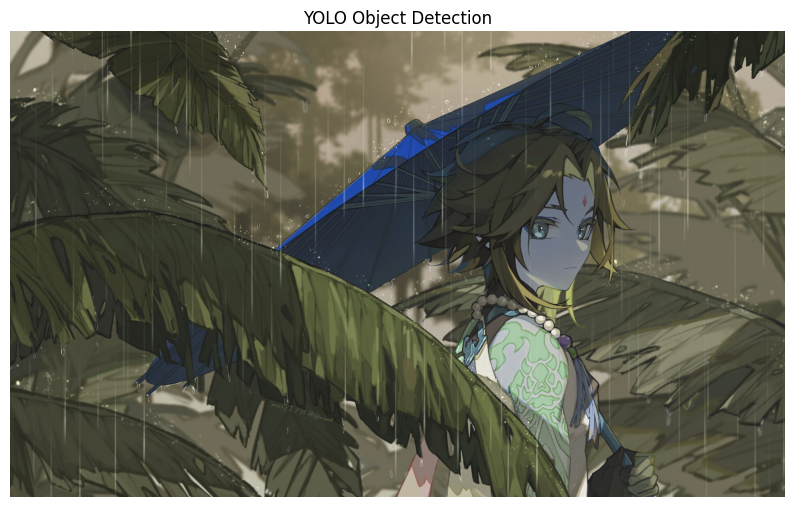

In [9]:

annotated_image = result.plot()

annotated_image = cv2.cvtColor(
    annotated_image,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(10, 8))

plt.imshow(annotated_image)

plt.title(
    "YOLO Object Detection"
)

plt.axis("off")

plt.show()

STEP 10: COUNT DETECTED OBJECTS

In [10]:
object_counts = {}

for obj in detected_objects:

    class_name = obj[0]

    if class_name in object_counts:

        object_counts[class_name] += 1

    else:

        object_counts[class_name] = 1

STEP 11: DISPLAY OBJECT COUNT

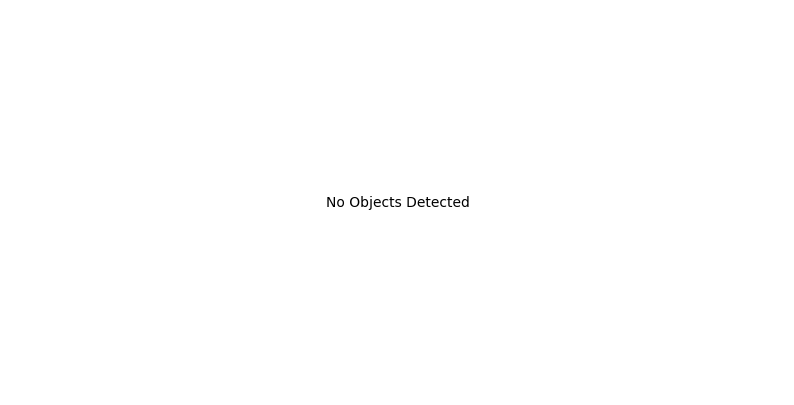

In [11]:
plt.figure(figsize=(10, 5))

if len(object_counts) > 0:

    plt.bar(
        object_counts.keys(),
        object_counts.values()
    )

    plt.xlabel("Object Class")

    plt.ylabel("Number of Objects")

    plt.title(
        "Detected Object Count"
    )

    plt.xticks(rotation=45)

else:

    plt.text(
        0.5,
        0.5,
        "No Objects Detected",
        ha="center",
        va="center"
    )

    plt.axis("off")

plt.show()


STEP 12: CALCULATE DETECTION STATISTICS

In [12]:
total_objects = len(detected_objects)

if total_objects > 0:

    average_confidence = np.mean(
        [
            obj[1]
            for obj in detected_objects
        ]
    )

else:

    average_confidence = 0

inference_time = result.speed["inference"]

 STEP 13: DISPLAY DETECTION SUMMARY

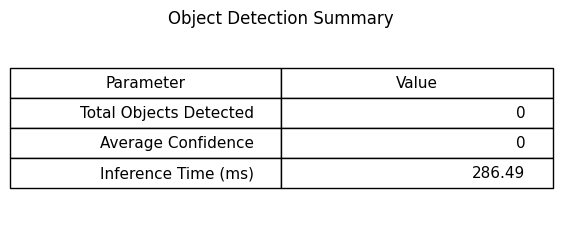

In [13]:
summary = [
    ["Total Objects Detected", total_objects],
    ["Average Confidence", round(average_confidence, 3)],
    ["Inference Time (ms)", round(inference_time, 2)]
]

fig, ax = plt.subplots(figsize=(7, 2.5))

ax.axis("off")

table = ax.table(
    cellText=summary,
    colLabels=["Parameter", "Value"],
    loc="center"
)

table.auto_set_font_size(False)

table.set_fontsize(11)

table.scale(1, 1.8)

plt.title(
    "Object Detection Summary"
)

plt.show()

QUESTIONS AND ANSWERS


Q1. Differentiate between image classification, object detection and image segmentation.

Answer:
Image classification assigns a class label to the complete image.

Object detection identifies objects and provides their class labels and bounding boxes.

Image segmentation assigns labels to individual pixels or regions of an image.

Q2. Explain the working principle of YOLO.

Answer:
YOLO stands for You Only Look Once.

It processes the complete image using a deep learning neural network and predicts bounding boxes, class labels and confidence scores.

YOLO performs detection in a single main detection process, which makes it suitable for fast object detection.

Q3. Compare YOLO, SSD and Faster R-CNN based on speed, accuracy and practical applications.

Answer:
YOLO and SSD are single-stage object detection methods designed for fast detection.

Faster R-CNN is a two-stage object detection method that first generates region proposals and then performs classification and localization.

YOLO and SSD are commonly suitable for applications where fast inference is important, while Faster R-CNN uses a more computationally intensive two-stage approach.

Q4. What is a bounding box? Why is it important?

Answer:
A bounding box is a rectangular box surrounding a detected object in an image.

It is important because it provides the location and approximate size of the detected object.

Q5. Explain the significance of confidence score and IoU.

Answer:
A confidence score represents the model's confidence in a particular object detection.

IoU stands for Intersection over Union.

It measures the overlap between the predicted bounding box and the ground-truth bounding box.

A higher IoU indicates greater overlap between the predicted and actual bounding boxes.

Q6. What are the advantages of using pre-trained deep learning models over traditional image processing?

Answer:
Pre-trained deep learning models have already learned useful visual features from large datasets.

They reduce the need to train a complete model from the beginning and can identify complex patterns.

Traditional image processing generally depends more on manually designed features and rules.

Q7. Why are datasets such as MS COCO and Pascal VOC widely used?

Answer:
MS COCO and Pascal VOC contain labeled images with different object categories and localization information.

They are widely used for training, testing and evaluating object detection algorithms.

Q8. Mention five real-world applications of object detection.

Answer:

1. Autonomous vehicles
2. Surveillance systems
3. Healthcare
4. Retail analytics
5. Industrial inspection

Q9. What challenges are commonly encountered while detecting objects in complex real-world environments?

Answer:

Common challenges include:

1. Poor lighting
2. Object occlusion
3. Overlapping objects
4. Small objects
5. Complex backgrounds
6. Different object sizes
7. Camera movement
8. Low-quality images

Q10. How can object detection systems be further improved?

Answer:

Object detection systems can be improved using:

1. Larger and more diverse datasets
2. Data augmentation
3. Improved deep learning architectures
4. Better feature extraction
5. Improved training techniques
6. Model optimization
7. Better hardware
8. Recent computer vision techniques

RESULT

The object detection and recognition system was successfully implemented using a pre-trained YOLO deep learning model.

Objects were identified and localized using bounding boxes, class labels and confidence scores.

The experiment demonstrated the practical application of deep learning-based object detection for identifying and localizing multiple objects in images.
